<a href="https://colab.research.google.com/github/mangeshdhuri11x-art/CE07-Roll_No_Machine-Learning-Lab/blob/main/ML_Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name :Mangesh Dhuri

Batch :CE1


Roll Number :CE07



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA

# Load Breast Cancer Wisconsin Diagnostic dataset
data = load_breast_cancer()

# Create DataFrame containing 30 numerical features
df = pd.DataFrame(data.data, columns=data.feature_names)

# Convert target labels:
# Original sklearn target: 0 = malignant, 1 = benign
df["diagnosis"] = np.where(data.target == 0, "M", "B")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

Number of samples: 569
Number of features: 30

Missing values:
0

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Diagnosis class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


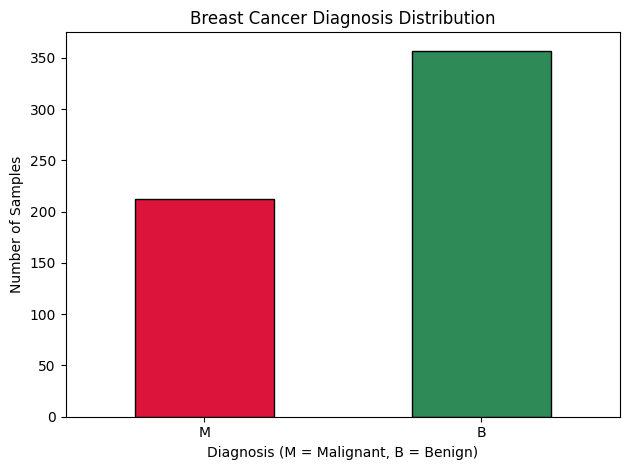

In [ ]:
# Dataset dimensions
print("Number of samples:", df.shape[0])
print("Number of features:", len(data.feature_names))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Summary statistics
print("\nSummary statistics:")
display(df.describe().T)

# Diagnosis class distribution
print("\nDiagnosis class distribution:")
print(df["diagnosis"].value_counts())

# Visualize class distribution
df["diagnosis"].value_counts().reindex(["M", "B"]).plot(
    kind="bar",
    color=["crimson", "seagreen"],
    edgecolor="black"
)
plt.title("Breast Cancer Diagnosis Distribution")
plt.xlabel("Diagnosis (M = Malignant, B = Benign)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [ ]:
# Select the 30 numerical features
X = df[data.feature_names].copy()

# Remove metadata if present
X = X.drop(columns=["id"], errors="ignore")

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature dimensions:", X.shape)
print("Scaled feature dimensions:", X_scaled.shape)

print("\nMean of first five scaled features:")
print(np.round(X_scaled.mean(axis=0)[:5], 4))

print("\nStandard deviation of first five scaled features:")
print(np.round(X_scaled.std(axis=0)[:5], 4))

# Ground-truth labels for evaluation
y_true = data.target

Original feature dimensions: (569, 30)
Scaled feature dimensions: (569, 30)

Mean of first five scaled features:
[-0.  0. -0. -0. -0.]

Standard deviation of first five scaled features:
[1. 1. 1. 1. 1.]


# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [ ]:
# Compute pairwise Euclidean distances
distance_condensed = pdist(X_scaled, metric="euclidean")
distance_matrix = squareform(distance_condensed)

print("Distance matrix shape:", distance_matrix.shape)
print("Distance between sample 1 and sample 2:",
      round(distance_matrix[0, 1], 4))

# Construct a weighted complete graph
G = nx.Graph()
G.add_nodes_from(range(len(X_scaled)))

n = len(X_scaled)

for i in range(n):
    for j in range(i + 1, n):
        G.add_edge(
            i,
            j,
            weight=float(distance_matrix[i, j])
        )

print("\nNumber of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Distance matrix shape: (569, 569)
Distance between sample 1 and sample 2: 10.3185

Number of nodes: 569
Number of edges: 161596


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [ ]:
# Compute the Minimum Spanning Tree
mst = nx.minimum_spanning_tree(
    G,
    weight="weight",
    algorithm="kruskal"
)

# Extract MST edges and weights
mst_edges = [
    (u, v, attributes["weight"])
    for u, v, attributes in mst.edges(data=True)
]

mst_edges_df = pd.DataFrame(
    mst_edges,
    columns=["Node 1", "Node 2", "Weight"]
)

print("MST nodes:", mst.number_of_nodes())
print("MST edges:", mst.number_of_edges())
print("Total MST weight:", round(mst.size(weight="weight"), 4))

print("\nFive largest MST edges:")
display(mst_edges_df.sort_values(
    "Weight", ascending=False
).head())

MST nodes: 569
MST edges: 568
Total MST weight: 1393.8521

Five largest MST edges:


,Node 1,Node 2,Weight
543,461,503,12.299945
111,68,152,10.476075
193,116,213,8.826434
326,212,461,8.268542
181,108,122,8.077984


# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [ ]:
# Sort MST edges in descending order of weight
sorted_edges = sorted(
    mst.edges(data=True),
    key=lambda edge: edge[2]["weight"],
    reverse=True
)

# Number of desired clusters
K = 2

# Remove the K-1 largest edges
mst_cluster = mst.copy()

edges_to_remove = [
    (u, v)
    for u, v, attributes in sorted_edges[:K - 1]
]

mst_cluster.remove_edges_from(edges_to_remove)

# Identify connected components
components = list(nx.connected_components(mst_cluster))

print("Number of clusters:", len(components))
print("Removed edge(s):", edges_to_remove)

# Assign a cluster label to each sample
cluster_labels = np.zeros(len(X_scaled), dtype=int)

for cluster_id, component in enumerate(components):
    for node in component:
        cluster_labels[node] = cluster_id

# Display cluster sizes
print("\nCluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())

# Compare clusters with true diagnosis
comparison = pd.crosstab(
    pd.Series(cluster_labels, name="MST Cluster"),
    pd.Series(
        np.where(y_true == 0, "Malignant", "Benign"),
        name="Actual Diagnosis"
    )
)

print("\nCluster vs. actual diagnosis:")
display(comparison)

Number of clusters: 2
Removed edge(s): [(461, 503)]

Cluster sizes:
0    567
1      2
Name: count, dtype: int64

Cluster vs. actual diagnosis:


Actual Diagnosis,Benign,Malignant
MST Cluster,,
0,357,210
1,0,2


# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [ ]:
# Evaluation metrics
sil_score = silhouette_score(
    X_scaled,
    cluster_labels,
    metric="euclidean"
)

ari = adjusted_rand_score(
    y_true,
    cluster_labels
)

nmi = normalized_mutual_info_score(
    y_true,
    cluster_labels
)

# Display results
results = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Adjusted Rand Index (ARI)",
        "Normalized Mutual Information (NMI)"
    ],
    "Score": [
        sil_score,
        ari,
        nmi
    ]
})

print("MST Clustering Evaluation Results:")
display(results.round(4))

MST Clustering Evaluation Results:


,Metric,Score
0,Silhouette Score,0.6607
1,Adjusted Rand Index (ARI),0.0048
2,Normalized Mutual Information (NMI),0.0102


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

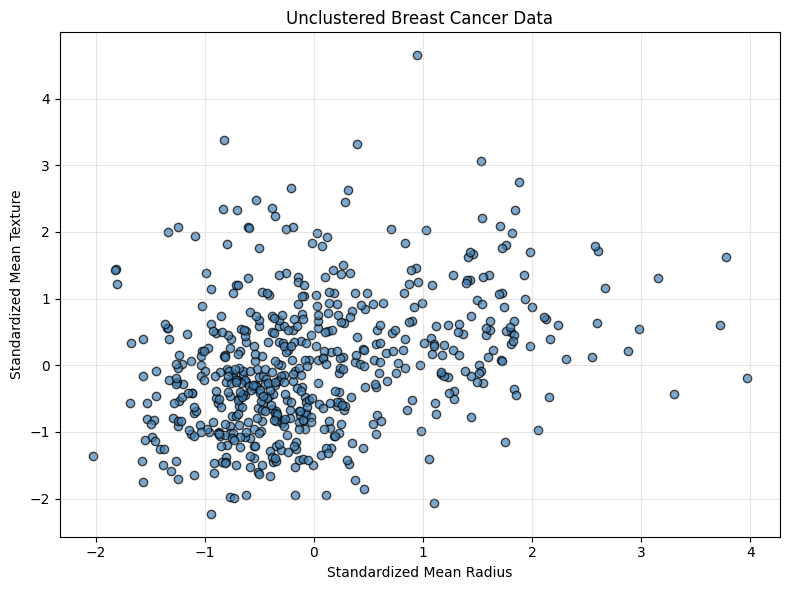

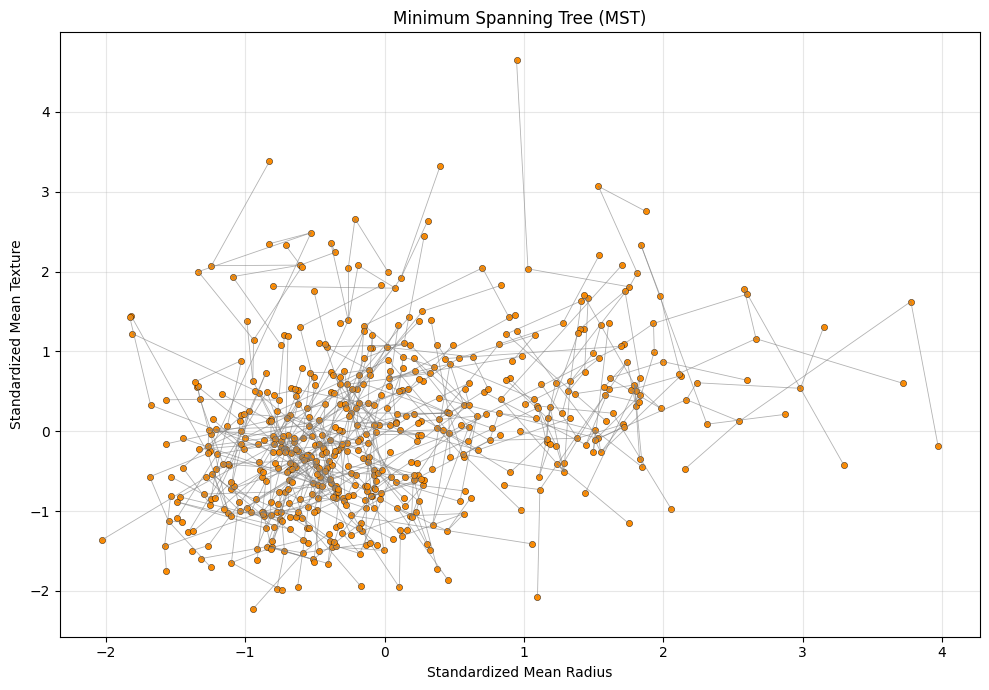

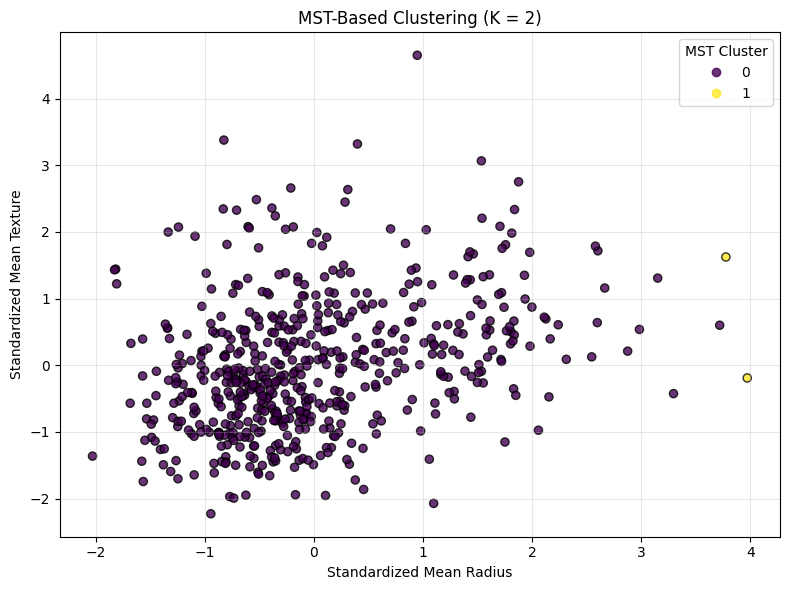

Task 8 completed successfully!
Three visualizations generated.


In [ ]:

# ============================================================
# TASK 8: VISUALIZE MST AND GRAPH-BASED CLUSTERS
# ============================================================

# Select two features for 2D visualization
# Feature 0 = mean radius
# Feature 1 = mean texture

X_2d = X_scaled[:, :2]

# ------------------------------------------------------------
# Plot 1: Unclustered standardized data points
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    color="steelblue",
    edgecolor="black",
    alpha=0.7
)

plt.title("Unclustered Breast Cancer Data")
plt.xlabel("Standardized Mean Radius")
plt.ylabel("Standardized Mean Texture")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: Minimum Spanning Tree (MST)
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

# Draw MST edges using the first two feature coordinates
for u, v in mst.edges():
    plt.plot(
        [X_2d[u, 0], X_2d[v, 0]],
        [X_2d[u, 1], X_2d[v, 1]],
        color="gray",
        linewidth=0.6,
        alpha=0.6
    )

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    color="darkorange",
    s=20,
    edgecolor="black",
    linewidth=0.3
)

plt.title("Minimum Spanning Tree (MST)")
plt.xlabel("Standardized Mean Radius")
plt.ylabel("Standardized Mean Texture")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 3: Final MST-based clusters (K = 2)
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=35,
    edgecolor="black",
    alpha=0.8
)

plt.title("MST-Based Clustering (K = 2)")
plt.xlabel("Standardized Mean Radius")
plt.ylabel("Standardized Mean Texture")
plt.legend(
    *scatter.legend_elements(),
    title="MST Cluster"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Task 8 completed successfully!")
print("Three visualizations generated.")


# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.